In [1]:
from google.colab import files
uploaded = files.upload()

Saving sales_data_cleaned.csv to sales_data_cleaned.csv


In [2]:

import pandas as pd
from google.colab import files

# STEP 1: Read the uploaded dataset
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# STEP 2: Inspect the original dataset
print("===== ORIGINAL DATASET =====")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# STEP 3: Clean column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# STEP 4: Remove duplicate rows
df = df.drop_duplicates().copy()

# STEP 5: Clean text columns
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].apply(
        lambda value: value.strip()
        if isinstance(value, str) else value
    )
    df[column] = df[column].replace("", pd.NA)

# STEP 6: Convert the date column
if "date" in df.columns:
    df["date"] = pd.to_datetime(
        df["date"], errors="coerce"
    )

# STEP 7: Convert numeric columns
for column in ["quantity", "unit_price", "customer_age"]:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column], errors="coerce"
        )

# STEP 8: Fill missing numeric values with the median
for column in df.select_dtypes(include="number").columns:
    if df[column].isnull().any():
        median_value = df[column].median()
        if pd.notna(median_value):
            df[column] = df[column].fillna(median_value)

# STEP 9: Fill missing text values with the mode
for column in df.select_dtypes(include="object").columns:
    if df[column].isnull().any():
        mode_values = df[column].mode(dropna=True)
        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])

# STEP 10: Remove rows with invalid dates
if "date" in df.columns:
    df = df.dropna(subset=["date"]).copy()

# STEP 11: Remove invalid quantities and prices
if "quantity" in df.columns:
    df = df[df["quantity"] > 0].copy()

if "unit_price" in df.columns:
    df = df[df["unit_price"] >= 0].copy()

# STEP 12: Calculate sales
if {"quantity", "unit_price"}.issubset(df.columns):
    df["sales"] = df["quantity"] * df["unit_price"]

# STEP 13: Save the cleaned dataset
output_file = "sales_data_cleaned.csv"
df.to_csv(output_file, index=False)

# STEP 14: Verify the cleaned dataset
print("\n===== CLEANED DATASET =====")
print(df.head())

print("\nFinal dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

print("\nTask 1 cleaning completed!")

# STEP 15: Download the cleaned CSV to your phone
files.download(output_file)


===== ORIGINAL DATASET =====
         date   product  quantity  unit_price region payment_method  \
0  2025-01-02    Laptop       2.0     50000.0  North           Card   
1  2025-01-03     Phone       1.0     20000.0  South            UPI   
2  2025-01-05     Mouse       3.0       500.0   East           Cash   
3  2025-01-06  Keyboard       2.0      1200.0   West           Card   
4  2025-01-08    Laptop       1.0     52000.0  North           Card   

   customer_age     sales  
0          25.0  100000.0  
1          31.0   20000.0  
2          22.0    1500.0  
3          29.0    2400.0  
4          42.0   52000.0  

Dataset shape: (9, 8)

Column names:
['date', 'product', 'quantity', 'unit_price', 'region', 'payment_method', 'customer_age', 'sales']

Data types:
date               object
product            object
quantity          float64
unit_price        float64
region             object
payment_method     object
customer_age      float64
sales             float64
dtype: object

Mis

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving sales_data_cleaned.csv to sales_data_cleaned (1).csv
DATASET OVERVIEW
Rows and columns: (9, 8)

Column names:
['date', 'product', 'quantity', 'unit_price', 'region', 'payment_method', 'customer_age', 'sales']

DESCRIPTIVE STATISTICS
              date   product  quantity    unit_price region payment_method  \
count            9         9  9.000000      9.000000      9              9   
unique           9         4       NaN           NaN      4              3   
top     2025-01-02  Keyboard       NaN           NaN   East           Card   
freq             1         3       NaN           NaN      3              4   
mean           NaN       NaN  2.111111  14911.111111    NaN            NaN   
std            NaN       NaN  1.054093  21425.478084    NaN            NaN   
min            NaN       NaN  1.000000    500.000000    NaN            NaN   
25%            NaN       NaN  1.000000    700.000000    NaN            NaN   
50%            NaN       NaN  2.000000   1200.000000    Na

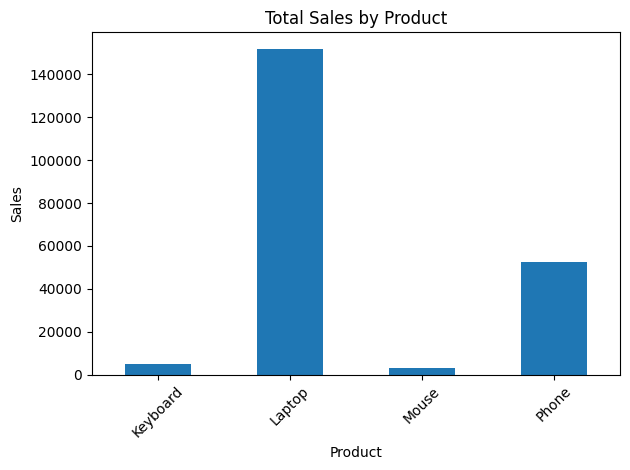


EDA ANALYSIS COMPLETED!


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Upload your cleaned CSV if it is not already available
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("DATASET OVERVIEW")
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDESCRIPTIVE STATISTICS")
print(df.describe(include="all"))

print("\nMISSING VALUES")
print(df.isnull().sum())

# Identify numerical outliers using the IQR method
print("\nOUTLIER CHECK")
for col in df.select_dtypes(include="number").columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ]
    print(col, "outliers:", len(outliers))

# Business questions
if "sales" in df.columns:
    print("\nTOTAL SALES:", df["sales"].sum())
    print("AVERAGE SALE:", df["sales"].mean())

if "product" in df.columns and "sales" in df.columns:
    print("\nSALES BY PRODUCT")
    print(df.groupby("product")["sales"].sum().sort_values(ascending=False))

if "region" in df.columns and "sales" in df.columns:
    print("\nSALES BY REGION")
    print(df.groupby("region")["sales"].sum().sort_values(ascending=False))

# Visualize sales by product
if "product" in df.columns and "sales" in df.columns:
    df.groupby("product")["sales"].sum().plot(
        kind="bar", title="Total Sales by Product"
    )
    plt.xlabel("Product")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

print("\nEDA ANALYSIS COMPLETED!")
